# Geometric solution of transitive inference
Coming off of the insights from the `minimal_model.ipynb` notebook, we want to outline the geometric solution in this notebook.

## Preliminaries
Before we get started, we have to remark about the properties of polar vectors. While a vector in $\mathbb{R}^2$ can be written as $(x,y)$ via Cartesian coordinates, we can write vectors in $\mathbb{R}^2$ via polar coordinates $(r, \theta)$ where $r\geq 0$ and $\theta\in [0,2\pi)$.

However, how do we perform dot products? The dot product of two vectors $(x_1,y_1),(x_2,y_2)\in\mathbb{R}^2$ is simply 
$$
\langle (x_1,y_1),(x_2,y_2) \rangle = x_1\cdot x_2 + y_1\cdot y_2.
$$
To derive the formula of the dot product for two polar vectors $(r_1,\theta_1),(r_2,\theta_2)$, we first convert them to cartesian coordinates via
$$
(r,\theta)=(r\cos \theta, r\sin \theta).
$$
Hence, we can write
$$
(r_1,\theta_1)\cdot (r_2,\theta_2)=r_1 r_2 (\cos \theta_1 \cos \theta_2 + \sin \theta_1 \sin \theta_2)
$$
which we can simplify via the cosine difference identity into
$$
(r_1,\theta_1)\cdot (r_2,\theta_2)=r_1 r_2 \cos(\theta_1 - \theta_2).
$$

## Imports

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

## Define vectors

In [2]:
starting_angle = 0
angle_increase = np.pi/8
num_stimuli = 5

In [3]:
angles = [starting_angle + i*angle_increase for i in range(num_stimuli)]
angles

[0.0,
 0.39269908169872414,
 0.7853981633974483,
 1.1780972450961724,
 1.5707963267948966]

In [4]:
radii = [1,]*num_stimuli
radii

[1, 1, 1, 1, 1]

In [5]:
stimuli = np.vstack((radii, angles))
stimuli.shape

(2, 5)

In [6]:
# Convert polar → Cartesian
x = radii * np.cos(angles)
y = radii * np.sin(angles)

## Plot vectors

In [7]:
colors = ['tab:green', 'tab:red', 'tab:purple', 'tab:blue', 'tab:orange']
labels_key = ['E', 'D', 'C', 'B', 'A']
labels_query = ['E Query', 'D Query', 'C Query', 'B Query', 'A Query']

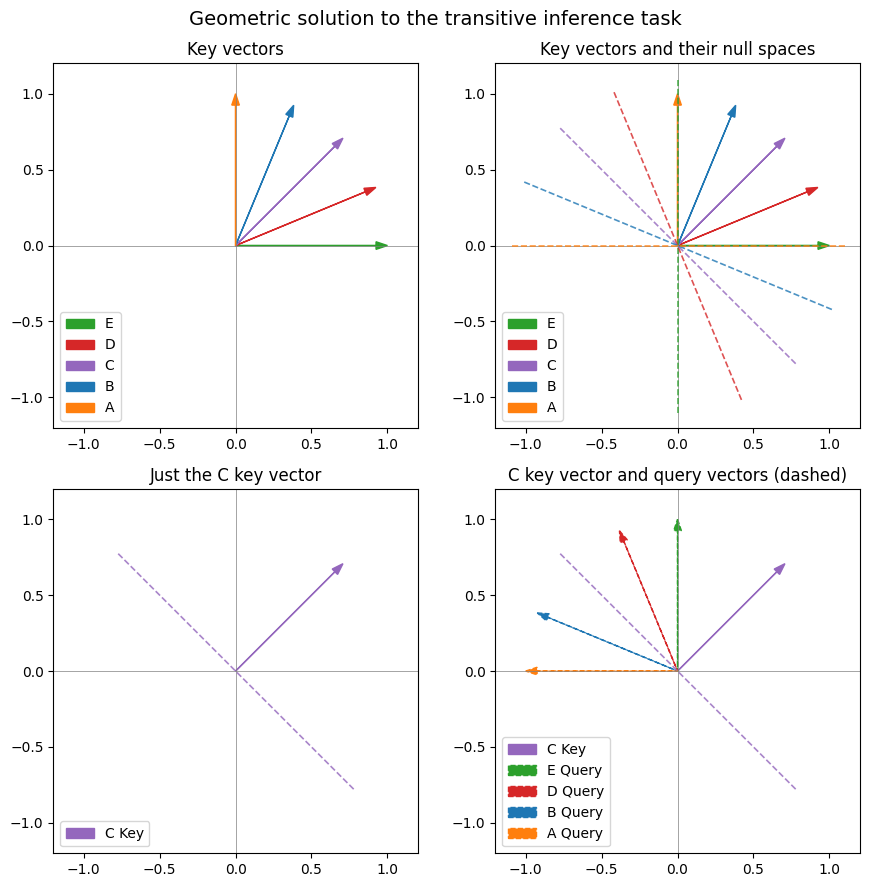

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9, 9))

## Key vector plot
axes[0,0].axhline(0, color='gray', linewidth=0.5)
axes[0,0].axvline(0, color='gray', linewidth=0.5)

for xi, yi, color, label in zip(x, y, colors, labels_key):
    axes[0,0].arrow(0, 0, xi, yi,
              head_width=0.05,
              length_includes_head=True,
              color=color, label=label)

axes[0,0].set_xlim(-1.2, 1.2)
axes[0,0].set_ylim(-1.2, 1.2)
axes[0,0].set_aspect('equal')
axes[0,0].set_title("Key vectors")
axes[0,0].legend(loc='lower left')

## Key vectors and their null spaces
axes[0,1].axhline(0, color='gray', linewidth=0.5)
axes[0,1].axvline(0, color='gray', linewidth=0.5)

for xi, yi, color, label in zip(x, y, colors, labels_key):

    # Original vector
    axes[0,1].arrow(0, 0, xi, yi,
              head_width=0.05,
              length_includes_head=True,
              color=color, label=label)

    # Null space direction (orthogonal vector)
    nx, ny = -yi, xi   # perpendicular vector

    # Normalize for consistent length
    norm = np.sqrt(nx**2 + ny**2)
    nx, ny = nx / norm, ny / norm

    # Plot dashed nullspace line (both directions)
    scale = 1.1  # length of dashed line
    axes[0,1].plot(
        [-nx*scale, nx*scale],
        [-ny*scale, ny*scale],
        linestyle='--',
        color=color,
        linewidth=1.2,
        alpha=0.8
    )

axes[0,1].set_xlim(-1.2, 1.2)
axes[0,1].set_ylim(-1.2, 1.2)
axes[0,1].set_aspect('equal')
axes[0,1].set_title("Key vectors and their null spaces")
axes[0,1].legend(loc='lower left')

## Just the C Key
axes[1,0].axhline(0, color='gray', linewidth=0.5)
axes[1,0].axvline(0, color='gray', linewidth=0.5)

xi, yi = x[2], y[2]

# Original vector
axes[1,0].arrow(0, 0, xi, yi,
            head_width=0.05,
            length_includes_head=True,
            color='tab:purple', label='C Key')

# Null space direction (orthogonal vector)
nx, ny = -yi, xi   # perpendicular vector

# Normalize for consistent length
norm = np.sqrt(nx**2 + ny**2)
nx, ny = nx / norm, ny / norm

# Plot dashed nullspace line (both directions)
scale = 1.1  # length of dashed line
axes[1,0].plot(
    [-nx*scale, nx*scale],
    [-ny*scale, ny*scale],
    linestyle='--',
    color='tab:purple',
    linewidth=1.2,
    alpha=0.8
)

axes[1,0].set_xlim(-1.2, 1.2)
axes[1,0].set_ylim(-1.2, 1.2)
axes[1,0].set_aspect('equal')
axes[1,0].set_title("Just the C key vector")
axes[1,0].legend(loc='lower left')

## C key plus query vectors
axes[1,1].axhline(0, color='gray', linewidth=0.5)
axes[1,1].axvline(0, color='gray', linewidth=0.5)

c_idx = 2  # index of the red vector

# --- Plot the original red vector + its nullspace line ---
xi, yi = x[c_idx], y[c_idx]

axes[1,1].arrow(0, 0, xi, yi,
          head_width=0.05,
          length_includes_head=True,
          color='tab:purple', label='C Key')

# Null space direction for the red vector (already what you had)
nx, ny = -yi, xi
norm = np.hypot(nx, ny)
nx, ny = nx / norm, ny / norm

scale = 1.1
axes[1,1].plot(
    [-nx * scale, nx * scale],
    [-ny * scale, ny * scale],
    linestyle='--',
    color='tab:purple',
    linewidth=1.2,
    alpha=0.8
)

# --- For all other vectors: rotate by 90° and plot dashed from origin ---
for i, (xi, yi, color, label) in enumerate(zip(x, y, colors, labels_query)):
    if i == c_idx:
        continue  # already handled

    # Rotate (xi, yi) by +90 degrees: (x', y') = (-y, x)
    xr, yr = -yi, xi
    # Optional: normalize to length 1
    norm = np.hypot(xr, yr)
    xr, yr = xr / norm, yr / norm

    axes[1,1].arrow(0, 0, xr, yr,
              head_width=0.05, ls='--',
              length_includes_head=True,
              color=color, label=label)

axes[1,1].set_xlim(-1.2, 1.2)
axes[1,1].set_ylim(-1.2, 1.2)
axes[1,1].set_aspect('equal')
axes[1,1].set_title("C key vector and query vectors (dashed)")
axes[1,1].legend(loc='lower left')

plt.suptitle("Geometric solution to the transitive inference task", fontsize=14)
plt.tight_layout()
plt.savefig('../../results/geometric_solution_ti.png')
plt.show()